In [11]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Dropout
from tensorflow.keras.models import Model

!conda update tensorflow -y

Retrieving notices: ...working... done

PackageNotInstalledError: Package is not installed in prefix.
  prefix: /opt/anaconda3
  package name: tensorflow




## My second analysis in applying CNN

In this analysis I would like to apply edges around the images and change the background colour in order to find out if I can fight my overfitting problem as shown in the first analysis, which included the resizing of images to see if that made any difference. 

Most of the methods will be the same as in the previous analysis because I want to make some changes in the preprocess_image_for_cnn method to show my progress in how I'm trying to fight the overfitting problem.

In [15]:
# Define the path to the training folder
training_dir = 'ASL_Dataset/Train'

# Function to preprocess an image
def preprocess_image_for_cnn(file_path, img_size=(64, 64)):
    # Read the image in grayscale
    img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
    
    # Apply Gaussian blur to reduce noise
    img = cv2.GaussianBlur(img, (5, 5), 0)
    
    # # Apply Canny Edge Detection to get the outline
    edges = cv2.Canny(img, threshold1=50, threshold2=150)
    
    # Resize to the desired input size
    edges = cv2.resize(edges, img_size)
    
    # # Normalize pixel values
    edges = edges / 255.0
    
    return img

The only difference with the processing of my images prior to the previous analysis I did is that this time the images are getting processed with edges around them. So there is a minor difference compared to the previous analysis.

Displaying preprocessed images from folder: A


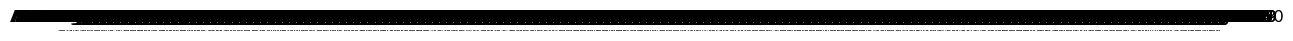

Displaying preprocessed images from folder: B


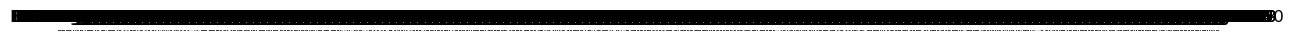

Displaying preprocessed images from folder: C


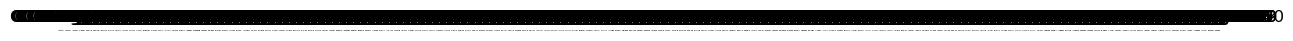

Displaying preprocessed images from folder: D


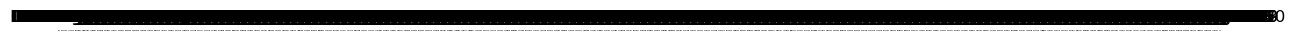

Displaying preprocessed images from folder: E


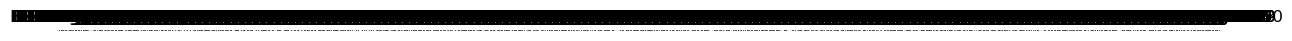

Displaying preprocessed images from folder: F


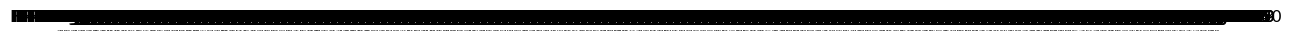

Displaying preprocessed images from folder: G


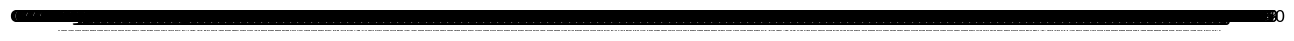

Displaying preprocessed images from folder: H


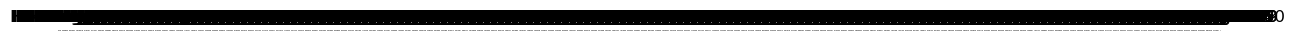

Displaying preprocessed images from folder: I


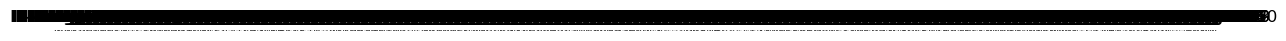

Displaying preprocessed images from folder: K


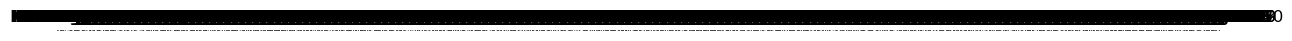

Displaying preprocessed images from folder: L


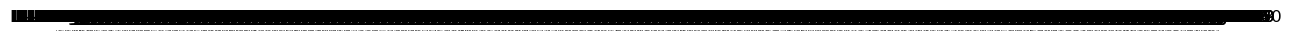

Displaying preprocessed images from folder: M


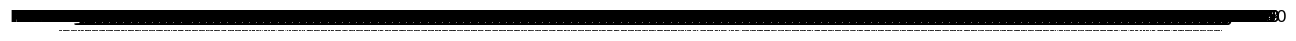

Displaying preprocessed images from folder: N


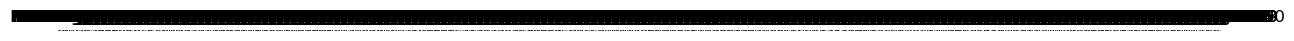

Displaying preprocessed images from folder: O


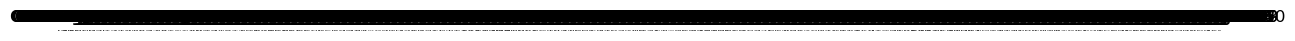

Displaying preprocessed images from folder: P


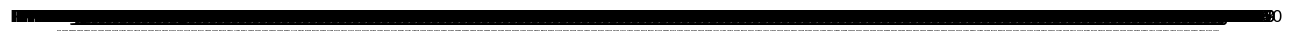

Displaying preprocessed images from folder: Q


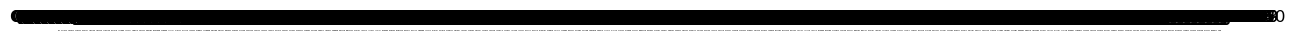

Displaying preprocessed images from folder: R


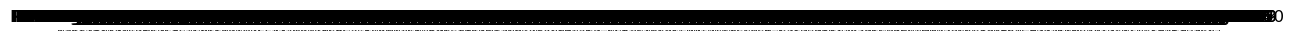

Displaying preprocessed images from folder: S


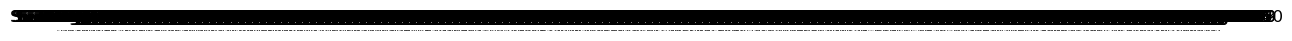

Displaying preprocessed images from folder: T


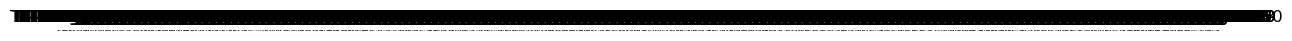

Displaying preprocessed images from folder: U


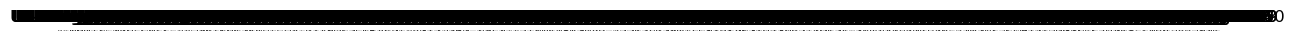

Displaying preprocessed images from folder: V


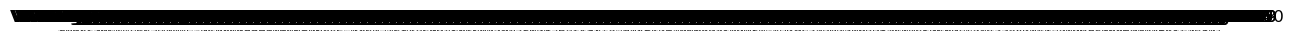

Displaying preprocessed images from folder: W


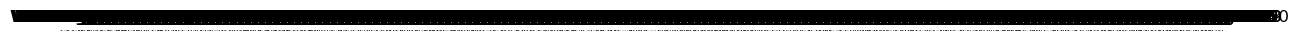

Displaying preprocessed images from folder: X


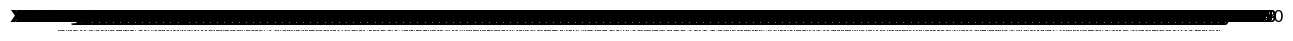

Displaying preprocessed images from folder: Y


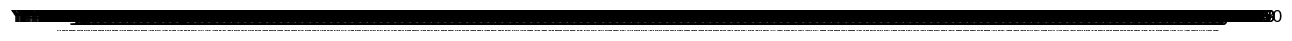

In [11]:
# Function to display images from each subfolder with preprocessing
def display_dataset_with_preprocessing(folder_path, num_images):
    
    # Folders I would like to exclude form the image processing
    exclude_folders = ["Space", "Nothing", "J", "Z"]
    
    # Iterate through each subfolder (a-z) in the training directory
    for subfolder in sorted(os.listdir(folder_path)):
        subfolder_path = os.path.join(folder_path, subfolder)
        
        # Check if the subfolder is a directory
        if os.path.isdir(subfolder_path) and subfolder.strip() not in exclude_folders:
            # Get all file names within the subfolder
            files = os.listdir(subfolder_path)
            
            # Limit to the first few files
            files = files[:num_images]

            # Display a few images from this subfolder
            print(f"Displaying preprocessed images from folder: {subfolder}")
            
            # Create a plot with num_images columns
            plt.figure(figsize=(15, 5))
            
            for i, file in enumerate(files):
                file_path = os.path.join(subfolder_path, file)
                
                # Preprocess image
                preprocessed_img = preprocess_image_for_cnn(file_path)
                
                # Display image in a subplot
                plt.subplot(1, num_images, i + 1)
                plt.imshow(preprocessed_img, cmap='gray')  
                plt.title(f'{subfolder} - Image {i + 1}')
                plt.axis('off')
        
        # Show all plots for this subfolder
        plt.show()

# Call the function to display preprocessed images
display_dataset_with_preprocessing(training_dir, num_images=1000)

To use my dataset for training databases on epochs, I had to develop a new method for creating it. The dataset that was previously created is only used for display. To check if I could truly read the dataset, I did this for myself. Because I made a mistake with the number of images in the previous method, which was set to a fixed amount of five, this was the reason the method had to be rewritten. I was able to specify how many images I wanted to display thanks to the rewrite I made for that method. 

As an extra extension to this method, because I forgot to do this earlier, I also want to make sure I'm not including the following 'letters': Nothing, Space, J, and the Z. I do not include these 'letters' because they are very hard to predict. Space and noting are both the equal, but not sowing anything as space or noting, and the Z and J are where the hand is making a motion in order to display the letters. These are not ideal to use for my training model, and that is why I exclude the out of the processing method.

In [1]:
def create_dataset(dataset_path, img_size=(64, 64)):
    X = []
    y = []
    labels = sorted(os.listdir(dataset_path))
    label_map = {label: idx for idx, label in enumerate(labels)}

    for label in labels:
        label_path = os.path.join(dataset_path, label)
        if os.path.isdir(label_path):
            for file in os.listdir(label_path):
                if not file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')):
                    print(f"Skipping non-image file: {file}")
                    continue
                file_path = os.path.join(label_path, file)
                try:
                    img = preprocess_image_for_cnn(file_path, img_size)
                    X.append(img)
                    y.append(label_map[label])
                except ValueError as e:
                    print(e)
                    continue

    X = np.array(X).reshape(-1, img_size[0], img_size[1], 1)  # Add channel dimension
    y = np.array(y)
    return X, y, label_map

In [7]:
def create_dataset2(dataset_path, img_size=(64, 64)):
    X = []
    y = []
    labels = sorted(os.listdir(dataset_path))
    label_map = {label: idx for idx, label in enumerate(labels)}

    for label in labels:
        label_path = os.path.join(dataset_path, label)
        if os.path.isdir(label_path):
            for file in os.listdir(label_path):
                if not file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff')):
                    print(f"Skipping non-image file: {file}")
                    continue
                file_path = os.path.join(label_path, file)
                try:
                    img = preprocess_image_for_cnn(file_path, img_size)
                    X.append(img)
                    y.append(label_map[label])
                except ValueError as e:
                    print(e)
                    continue

    X = np.array(X).reshape(-1, img_size[0], img_size[1], 1)  # Add channel dimension
    y = np.array(y)
    return X, y, label_map

my build_cnn_model method constructs a convolutional neural network (CNN) for image classification.

In [3]:
def build_cnn_model(input_shape, num_classes):
    model = Sequential([
        # Convolutional layers
        Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),

        # Flatten the feature map
        Flatten(),

        # Fully connected layers
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(num_classes, activation='softmax')
    ])
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

At first we start with proprocessing the images with edges at the size of 64 x 64 to see what happends.

In [13]:
# Create dataset
dataset_path = 'ASL_Dataset/Train'
X, y, label_map = create_dataset2(dataset_path, img_size=(64, 64))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the model
input_shape = (64, 64, 1) 
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test), batch_size=32)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

NameError: name 'preprocess_image_for_cnn' is not defined

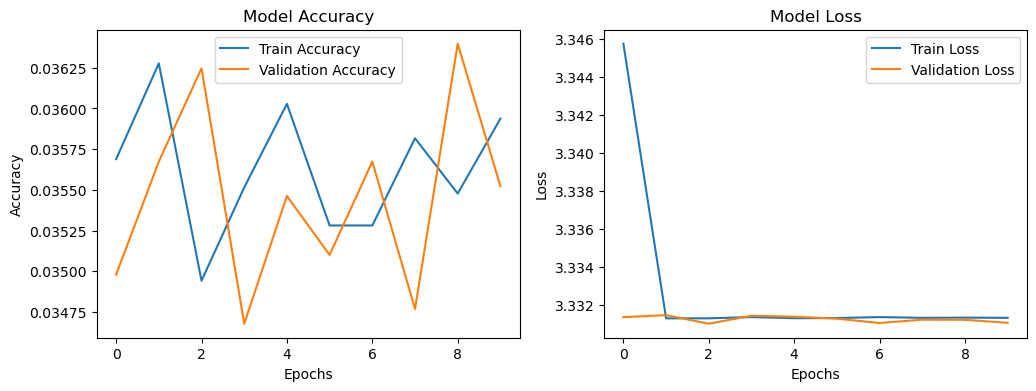

In [33]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

In [35]:
# Create dataset
dataset_path = 'ASL_Dataset/Train'
X, y, label_map = create_dataset2(dataset_path)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the model
input_shape = (32, 32, 1) 
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test), batch_size=32)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping non-image file: .ipynb_checkpoints
Skipping non-image file: .ipynb_checkpoints
Epoch 1/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 44s 10ms/step - accuracy: 0.7472 - loss: 0.9665 - val_accuracy: 0.9960 - val_loss: 0.0140
Epoch 2/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 40s 10ms/step - accuracy: 0.9882 - loss: 0.0395 - val_accuracy: 0.9964 - val_loss: 0.0114
Epoch 3/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 40s 10ms/step - accuracy: 0.9912 - loss: 0.0345 - val_accuracy: 0.9994 - val_loss: 0.0019
Epoch 4/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 38s 9ms/step - accuracy: 0.9940 - loss: 0.0272 - val_accuracy: 0.9993 - val_loss: 0.0034
Epoch 5/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 39s 9ms/step - accuracy: 0.9942 - loss: 0.0292 - val_accuracy: 0.9994 - val_loss: 0.0034
Epoch 6/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 41s 10ms/step - accuracy: 0.9957 - loss: 0.0224 - val_accuracy: 0.9969 - val_loss: 0.0181
Epoch 7/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 40s 10ms/step - accuracy: 0.9953 - loss: 0.0288 - val_accuracy: 0.9996 - val_los

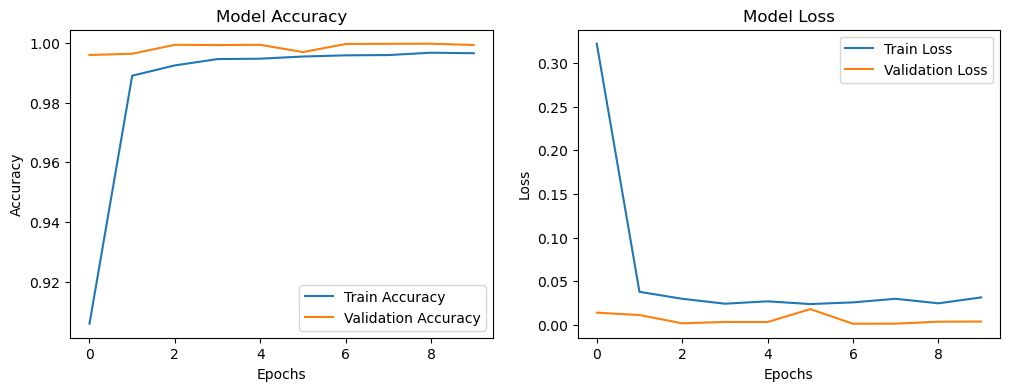

In [37]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

In [49]:
# Create dataset
dataset_path = 'ASL_Dataset/Train'
X, y, label_map = create_dataset2(dataset_path, img_size=(28, 28))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build the model
input_shape = (28, 28, 1) 
num_classes = len(label_map)
model = build_cnn_model(input_shape, num_classes)

# Train the model
history = model.fit(X_train, y_train, epochs=10, validation_data=(X_test, y_test), batch_size=32)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy:.2f}")

Skipping non-image file: .ipynb_checkpoints
Skipping non-image file: .ipynb_checkpoints
Epoch 1/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 33s 8ms/step - accuracy: 0.6803 - loss: 1.1903 - val_accuracy: 0.9820 - val_loss: 0.0633
Epoch 2/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 32s 8ms/step - accuracy: 0.9753 - loss: 0.0809 - val_accuracy: 0.9937 - val_loss: 0.0222
Epoch 3/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 31s 7ms/step - accuracy: 0.9842 - loss: 0.0532 - val_accuracy: 0.9903 - val_loss: 0.0320
Epoch 4/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 32s 8ms/step - accuracy: 0.9886 - loss: 0.0435 - val_accuracy: 0.9950 - val_loss: 0.0157
Epoch 5/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 31s 8ms/step - accuracy: 0.9903 - loss: 0.0386 - val_accuracy: 0.9875 - val_loss: 0.0509
Epoch 6/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 31s 8ms/step - accuracy: 0.9912 - loss: 0.0409 - val_accuracy: 0.9961 - val_loss: 0.0140
Epoch 7/10
4142/4142 ━━━━━━━━━━━━━━━━━━━━ 32s 8ms/step - accuracy: 0.9916 - loss: 0.0348 - val_accuracy: 0.9957 - val_loss: 0.

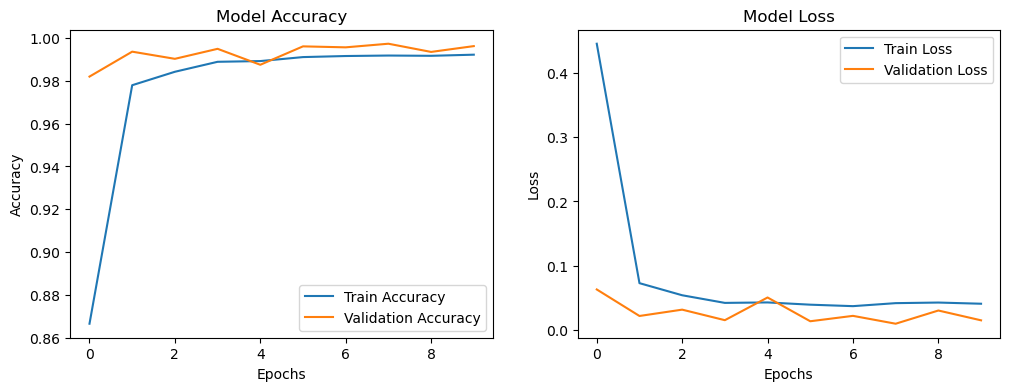

In [51]:
def plot_training_history(history):
    plt.figure(figsize=(12, 4))
    
    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    
    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.show()

# Call the function
plot_training_history(history)

In [49]:
def evaluate_model_per_class(model, X_test, y_test, label_map, images_per_class=50):

    # Reverse the label map to get class names
    reverse_label_map = {idx: label for label, idx in label_map.items()}
    
    # Group images by their true label
    class_indices = {label: np.where(y_test == idx)[0] for label, idx in label_map.items()}
    
    overall_accuracy = []
    
    for label, indices in class_indices.items():
        # Select a fixed number of images for the class
        if len(indices) < images_per_class:
            print(f"Not enough images for class '{label}'. Using {len(indices)} images.")
            selected_indices = indices
        else:
            selected_indices = np.random.choice(indices, size=images_per_class, replace=False)
        
        # Get the selected images and labels
        selected_images = X_test[selected_indices]
        true_labels = y_test[selected_indices]
        
        # Predict class probabilities
        predictions = model.predict(selected_images)
        predicted_labels = np.argmax(predictions, axis=1)
        
        # Calculate accuracy for this class
        class_accuracy = np.mean(predicted_labels == true_labels)
        overall_accuracy.append(class_accuracy)
        
        # Print results for this class
        print(f"Class '{label}' - Accuracy: {class_accuracy * 100:.2f}%")
        
        # Visualize a few images from this class
        plt.figure(figsize=(10, 5))
        for i in range(min(10, len(selected_images))):  # Show up to 10 images per class
            plt.subplot(2, 5, i + 1)
            plt.imshow(selected_images[i].reshape(28, 28), cmap='gray')  # Adjust size to match input
            true_label = reverse_label_map[true_labels[i]]
            predicted_label = reverse_label_map[predicted_labels[i]]
            color = 'green' if true_label == predicted_label else 'red'
            plt.title(f"True: {true_label}\nPred: {predicted_label}", color=color)
            plt.axis('off')
        plt.tight_layout()
        plt.show()
    
    # Compute overall accuracy
    mean_accuracy = np.mean(overall_accuracy)
    print(f"Overall accuracy across all classes: {mean_accuracy * 100:.2f}%")


Overall Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


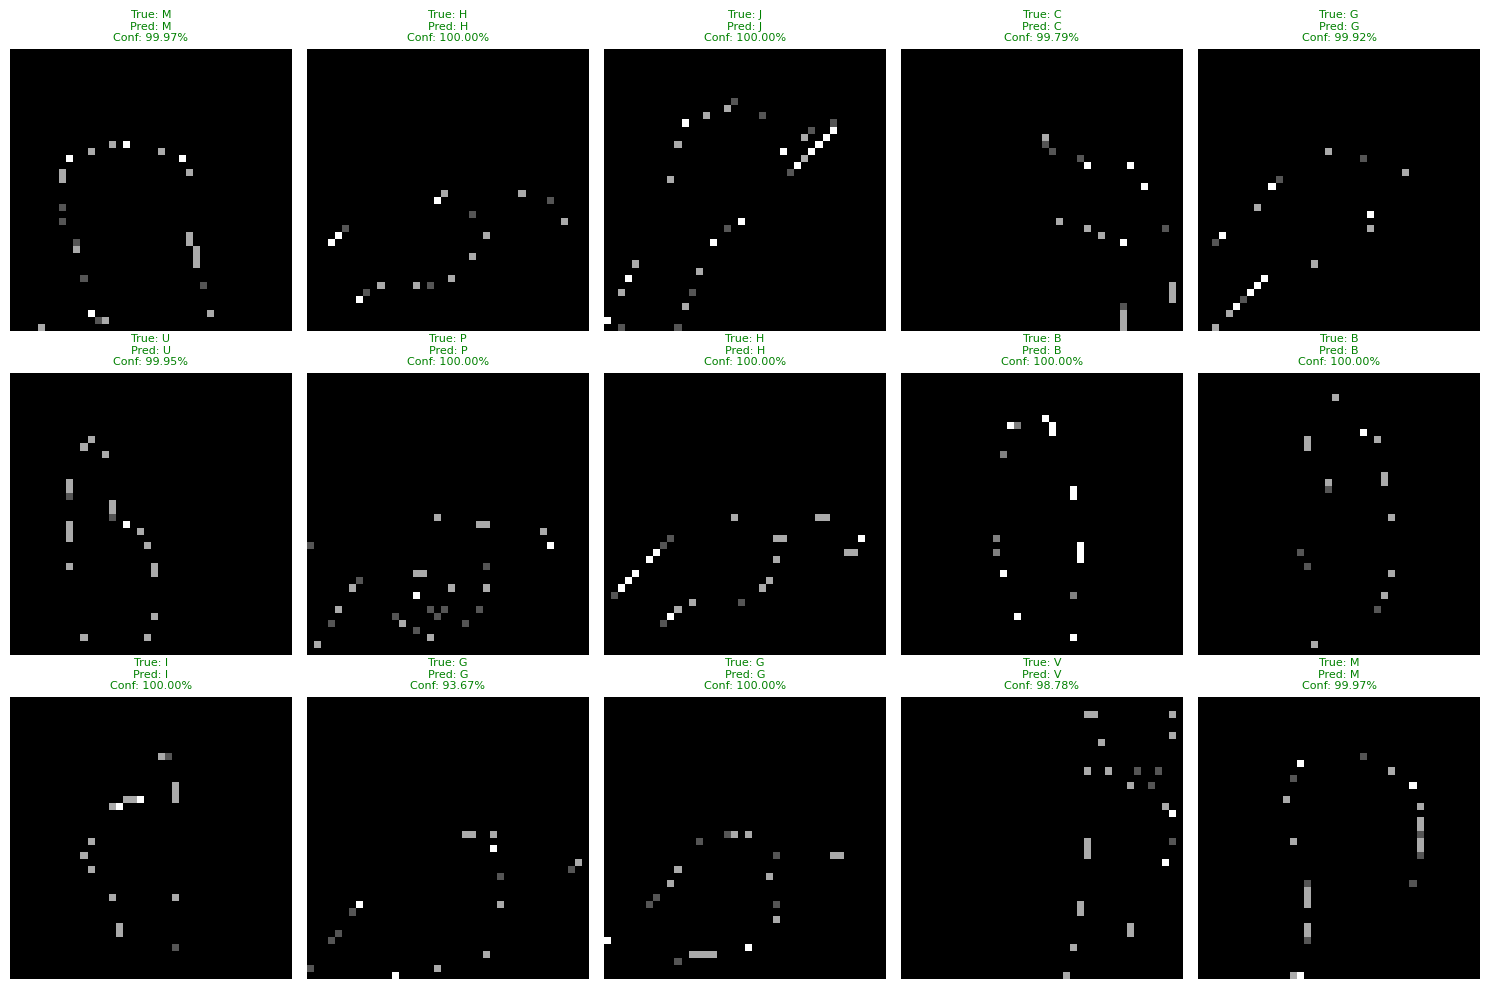

Per-Class Prediction Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━

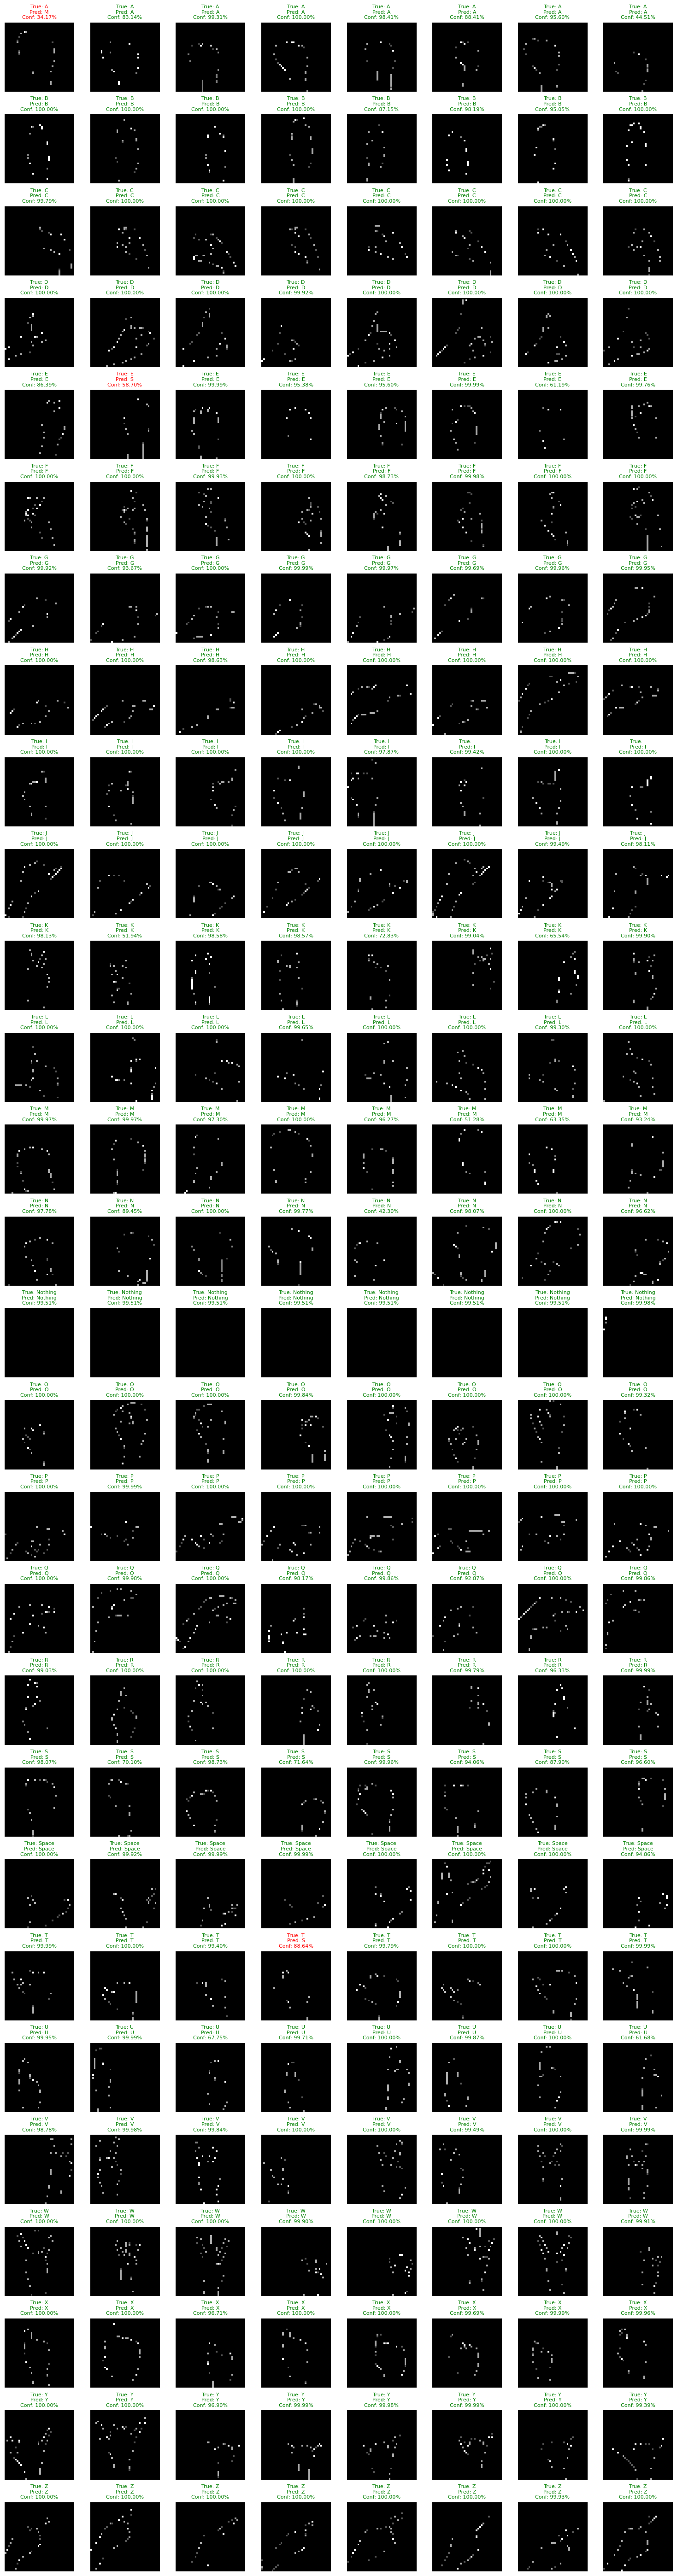

Class-Wise Accuracy Analysis:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Class 'A' - Accuracy: 87.50%


ValueError: cannot reshape array of size 1600 into shape (28,28)

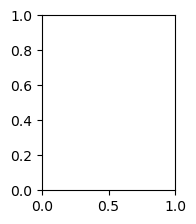

In [53]:
def analyze_model_predictions(model, X_test, y_test, label_map, img_size=(28, 28), num_predictions=15, num_per_class=8):
    
    # Convert labels if one-hot encoded
    if len(y_test.shape) > 1:
        y_test = np.argmax(y_test, axis=1)
    
    # Reverse label map for display
    reverse_label_map = {v: k for k, v in label_map.items()}
    
    # Overall predictions visualization
    print("Overall Prediction Analysis:")
    predictions = model.predict(X_test[:num_predictions])
    plt.figure(figsize=(15, 10))
    for i in range(num_predictions):
        plt.subplot(3, 5, i + 1)
        plt.imshow(X_test[i].reshape(img_size), cmap='gray')
        true_label = y_test[i]
        pred_label = np.argmax(predictions[i])
        is_correct = true_label == pred_label
        confidence = predictions[i][pred_label] * 100
        color = 'green' if is_correct else 'red'
        plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                  color=color, fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    # Per-class predictions visualization
    print("Per-Class Prediction Analysis:")
    class_samples = {cls: 0 for cls in range(len(label_map))}
    plt.figure(figsize=(15, len(label_map) * 2))
    for i, (img, true_label) in enumerate(zip(X_test, y_test)):
        if class_samples[true_label] < num_per_class:
            prediction = model.predict(img.reshape(1, *img_size, 1))
            pred_label = np.argmax(prediction)
            confidence = prediction[0][pred_label] * 100
            is_correct = true_label == pred_label
            color = 'green' if is_correct else 'red'
            
            plt.subplot(len(label_map), num_per_class, true_label * num_per_class + class_samples[true_label] + 1)
            plt.imshow(img.reshape(img_size), cmap='gray')
            plt.title(f"True: {reverse_label_map[true_label]}\nPred: {reverse_label_map[pred_label]}\nConf: {confidence:.2f}%",
                      color=color, fontsize=8)
            plt.axis('off')
            class_samples[true_label] += 1
        if all(count == num_per_class for count in class_samples.values()):
            break
    plt.tight_layout()
    plt.show()
    
    # Evaluate accuracy per class
    print("Class-Wise Accuracy Analysis:")
    evaluate_model_per_class(model, X_test, y_test, label_map, images_per_class=num_per_class)


analyze_model_predictions(model, 
                          X_test, 
                          y_test, 
                          label_map, 
                          img_size=(40, 40), 
                          num_predictions=15, 
                          num_per_class=8)


## Analysis 3 

In the thrid analyis i am adding an 

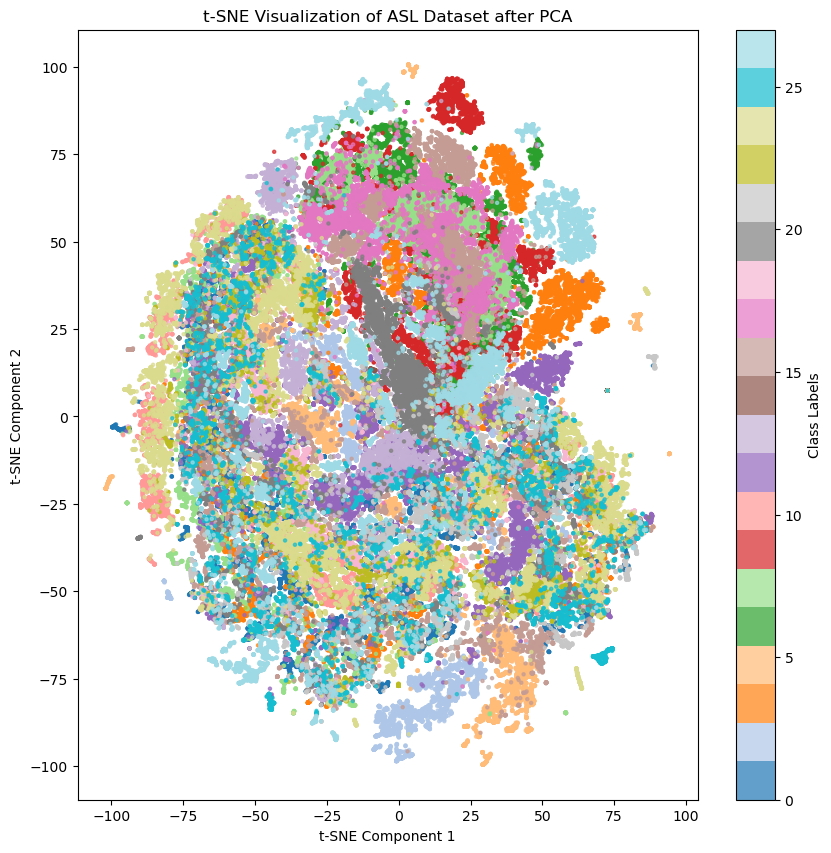

In [67]:
# Step 1: Create the dataset
X, y, label_map = create_dataset('ASL_Dataset/Train')

# Step 2: Flatten the images for dimensionality reduction
X_flat = X.reshape(X.shape[0], -1)

# Step 3: Apply PCA to reduce to 50 components
pca_components = 50
pca = PCA(n_components=pca_components, random_state=42)
X_reduced = pca.fit_transform(X_flat)

# Step 4: Apply t-SNE to reduce to 2 components
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_reduced)

# Step 5: Visualize the results
numeric_labels = LabelEncoder().fit_transform(y)
plt.figure(figsize=(10, 10))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=numeric_labels, cmap="tab20", s=5, alpha=0.7)
plt.colorbar(scatter, label='Aplhabet Letters')
plt.title("t-SNE Visualization of ASL Dataset with PCA")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

Since some of the values in this example, such as "Nothing," "Space," "J," and "Z," are currently useless for the research I'm doing, I filtered them out. Since these values are extremely challenging for the model to use, I decided to filter them out. The 'J' and 'Z' are hand gestures that require specific hand movements to form, which makes them challenging to use. Because of this, it is very challenging to capture these letters and incorporate them into the model. Regarding the "Space" and "Nothing" "letters," the images' names already make it clear what they are.

Labels: [0 0 0 0 0]
Label Map: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'Nothing': 14, 'O': 15, 'P': 16, 'Q': 17, 'R': 18, 'S': 19, 'Space': 20, 'T': 21, 'U': 22, 'V': 23, 'W': 24, 'X': 25, 'Y': 26, 'Z': 27}


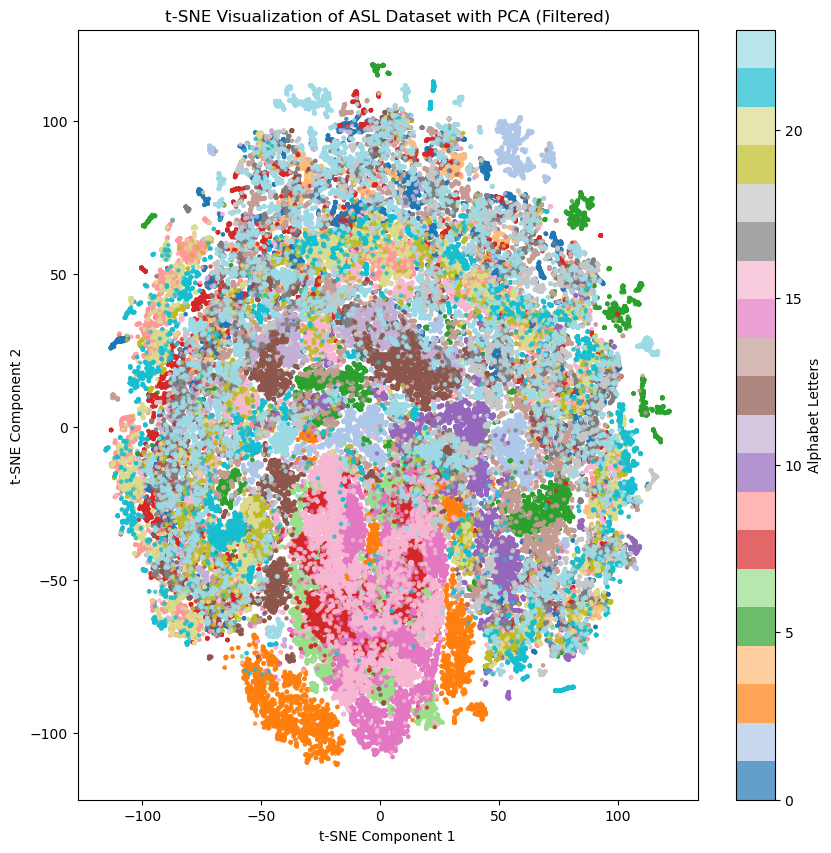

In [19]:
# Step 0: Load the dataset
X, y, label_map = create_dataset('ASL_Dataset/Train')

# Check the output of create_dataset
print("Labels:", y[:5])
print("Label Map:", label_map)

# Step 1: Generate or validate label_map if needed
# If label_map is not provided, create one from unique labels in `y`
if not label_map:
    unique_labels = np.unique(y) 
    label_map = {chr(65 + i): i for i in range(26)}
    label_map.update({'space': 26, 'nothing': 27})

# Step 2: Filter out unwanted classes
unwanted_classes = ['Space', 'Nothing', 'J', 'Z'] 
unwanted_indices = [label_map[label] for label in unwanted_classes if label in label_map]

# Create a mask for the desired classes
mask = ~np.isin(y, unwanted_indices)
X_filtered = X[mask]
y_filtered = y[mask]

# Step 3: Proceed with the rest of your pipeline
X_flat = X_filtered.reshape(X_filtered.shape[0], -1)
pca = PCA(n_components=50, random_state=42)
X_reduced = pca.fit_transform(X_flat)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_reduced)

# Step 4: Visualization
numeric_labels = LabelEncoder().fit_transform(y_filtered)
plt.figure(figsize=(10, 10))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=numeric_labels, cmap="tab20", s=5, alpha=0.7)
plt.colorbar(scatter, label='Alphabet Letters')
plt.title("t-SNE Visualization of ASL Dataset with PCA (Filtered)")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

If we comparsion this with the very first T-SNE you can clearly see that we lost somehow some clusters. Clusters that are labled with the color lime. As seen in the first picture in the left cornor of the "ball" you can see small groups of line cluster by each other which is missing in this ball of clusters. This will still does not say that it is bad, but it is strange. What I do notice is that there are a lot more dots everywhere and nowhere, which gives me an indication that the model is having trouble with some of the letters mapping properly.

## Using PCA and filter out values

I tried to create a new TSE modle where the PCA is not in applied to see how well our model would predicts certain values. 

Labels: [0 0 0 0 0]
Label Map: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'Nothing': 14, 'O': 15, 'P': 16, 'Q': 17, 'R': 18, 'S': 19, 'Space': 20, 'T': 21, 'U': 22, 'V': 23, 'W': 24, 'X': 25, 'Y': 26, 'Z': 27}


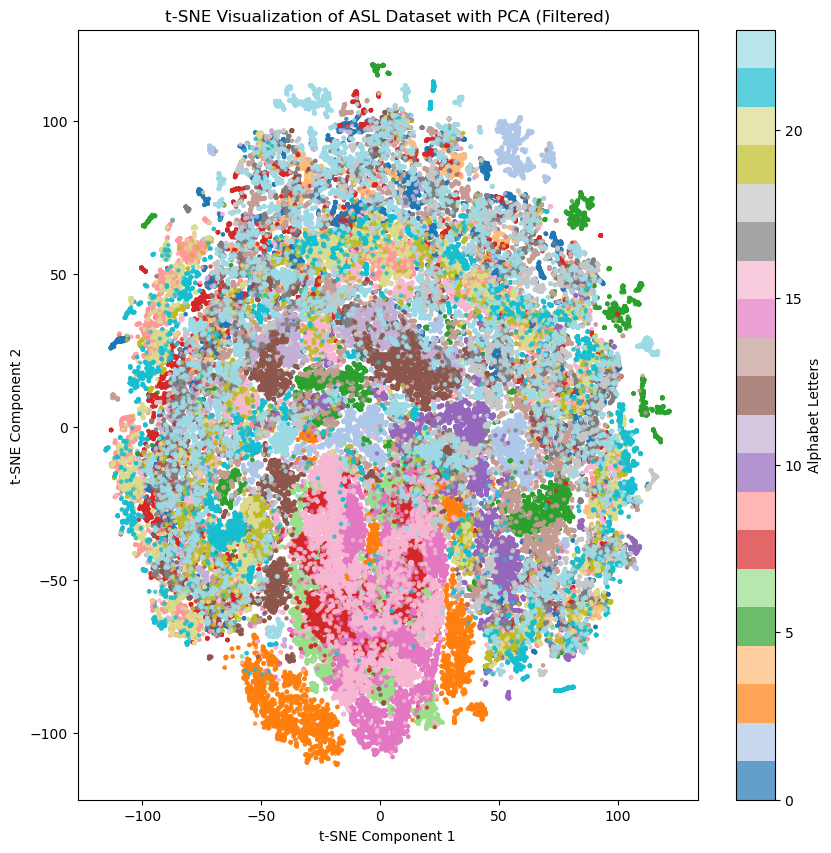

In [21]:
# Step 0: Load the dataset
X, y, label_map = create_dataset('ASL_Dataset/Train')

# Check the output of create_dataset
print("Labels:", y[:5])
print("Label Map:", label_map)

# Step 1: Generate or validate label_map if needed
# If label_map is not provided, create one from unique labels in `y`
if not label_map:
    unique_labels = np.unique(y) 
    label_map = {chr(65 + i): i for i in range(26)}
    label_map.update({'space': 26, 'nothing': 27})

# Step 2: Filter out unwanted classes
unwanted_classes = ['Space', 'Nothing', 'J', 'Z'] 
unwanted_indices = [label_map[label] for label in unwanted_classes if label in label_map]

# Create a mask for the desired classes
mask = ~np.isin(y, unwanted_indices)  
X_filtered = X[mask]
y_filtered = y[mask]

# Step 3: Proceed with the rest of your pipeline
X_flat = X_filtered.reshape(X_filtered.shape[0], -1)
X_reduced = pca.fit_transform(X_flat)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000)
X_tsne = tsne.fit_transform(X_reduced)

# Step 4: Visualization
numeric_labels = LabelEncoder().fit_transform(y_filtered)
plt.figure(figsize=(10, 10))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=numeric_labels, cmap="tab20", s=5, alpha=0.7)
plt.colorbar(scatter, label='Alphabet Letters')
plt.title("t-SNE Visualization of ASL Dataset without PCA")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.show()

## Conclusion and reasoning

I kept the same values filtered out but with the applying the PCA. I didnt apply the PCA because I was curious what the results where without the PCA if it made any differnce in how the clusters are structed in the plot. But if I make a comparison with the previous one (The one where a PCA is applied) I do not see any difference in the clusters. 

So my conclusion is that it does not matter if I filter out values like 'nothing,' 'space,' 'J,' and 'Z' and do not use the PCA. This is also the reason I want to move to the new dataset, which combines the two datasets we were studying. I'm hoping to find different values in this one. values that allow me to develop a good LLM (AI) for sign language comprehension.